# Customer & Restaurant Segementation

# Part 1 - Feature Engineering

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
# Load datasets 
customers = pd.read_csv("../data/raw/customers.csv")
restaurants = pd.read_csv("../data/raw/restaurants.csv")
orders = pd.read_csv("../data/raw/orders.csv")
deliveries = pd.read_csv("../data/raw/deliveries.csv")
drivers = pd.read_csv("../data/raw/drivers.csv")
reviews = pd.read_csv("../data/raw/reviews.csv")
payments = pd.read_csv("../data/raw/payments.csv")

In [3]:
orders["order_timestamp"] = pd.to_datetime(
    orders["order_timestamp"]
)

In [ ]:
# Data inspection
print("Customers:", customers.shape)
print("Restaurants:", restaurants.shape)
print("Orders:", orders.shape)
print("Deliveries:", deliveries.shape)
print("Drivers:", drivers.shape)
print("Reviews:", reviews.shape)
print("Payments:", payments.shape)

Customers: (1000, 5)
Restaurants: (200, 5)
Orders: (10000, 7)
Deliveries: (8481, 8)
Drivers: (300, 4)
Reviews: (8481, 5)
Payments: (10000, 5)


# Customer Feature Engineering

In [5]:
# Order-based features
customer_order_features = orders.groupby("customer_id").agg(
    total_orders=("order_id", "count"),
    avg_order_value=("order_amount", "mean"),
    total_spending=("order_amount", "sum")
).reset_index()

customer_order_features.head()

# Ordering Frequency
orders["order_month"] = orders["order_timestamp"].dt.to_period("M")
active_months = (
    orders.groupby("customer_id")["order_month"]
    .nunique()
    .reset_index(name="active_months")
)
active_months["ordering_frequency"] = (
    customer_order_features["total_orders"]
    / active_months["active_months"]
)

In [6]:
active_months = (
    orders.groupby("customer_id")["order_month"]
    .nunique()
    .reset_index(name="active_months")
)

customer_order_features = customer_order_features.merge(
    active_months,
    on="customer_id",
    how="left"
)

customer_order_features["ordering_frequency"] = (
    customer_order_features["total_orders"]
    / customer_order_features["active_months"]
)

In [7]:
# Weekend orders
orders["is_weekend"] = (
    orders["order_timestamp"].dt.dayofweek >= 5
)
weekend_orders = (
    orders.groupby("customer_id")["is_weekend"]
    .sum()
    .reset_index(name="weekend_orders")
)

In [8]:
# Late-Night Orders
order_hour = orders["order_timestamp"].dt.hour

orders["is_late_night"] = (
    (order_hour >= 22) |
    (order_hour < 5)
)
late_night_orders = (
    orders.groupby("customer_id")["is_late_night"]
    .sum()
    .reset_index(name="late_night_orders")
)

In [9]:
# Average Rating Given
customer_ratings = (
    reviews.groupby("customer_id")["rating"]
    .mean()
    .reset_index(name="avg_rating_given")
)

In [10]:
# Combine 
customer_features = customer_order_features.merge(
    weekend_orders,
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    late_night_orders,
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    customer_ratings,
    on="customer_id",
    how="left"
)

customer_features.head()

,customer_id,total_orders,avg_order_value,total_spending,active_months,ordering_frequency,weekend_orders,late_night_orders,avg_rating_given
0,C0001,9,1177.544444,10597.90,3,3.000000,1,5,3.777778
1,C0002,8,1376.162500,11009.30,3,2.666667,1,5,3.714286
2,C0003,11,1020.679091,11227.47,3,3.666667,4,2,3.600000
3,C0004,8,1088.231250,8705.85,3,2.666667,2,1,3.571429
4,C0005,5,678.588000,3392.94,3,1.666667,2,0,3.400000


In [11]:
# Check the result
print(customer_features.shape)
print(customer_features.columns.tolist())

(1000, 9)
['customer_id', 'total_orders', 'avg_order_value', 'total_spending', 'active_months', 'ordering_frequency', 'weekend_orders', 'late_night_orders', 'avg_rating_given']


In [12]:
print(customer_features.shape)
print(customer_features.columns.tolist())
print(customer_features.head())
print(customer_features.isnull().sum())

(1000, 9)
['customer_id', 'total_orders', 'avg_order_value', 'total_spending', 'active_months', 'ordering_frequency', 'weekend_orders', 'late_night_orders', 'avg_rating_given']
  customer_id  total_orders  avg_order_value  total_spending  active_months  \
0       C0001             9      1177.544444        10597.90              3   
1       C0002             8      1376.162500        11009.30              3   
2       C0003            11      1020.679091        11227.47              3   
3       C0004             8      1088.231250         8705.85              3   
4       C0005             5       678.588000         3392.94              3   

   ordering_frequency  weekend_orders  late_night_orders  avg_rating_given  
0            3.000000               1                  5          3.777778  
1            2.666667               1                  5          3.714286  
2            3.666667               4                  2          3.600000  
3            2.666667               2   

In [13]:
#  Preprocessing

# Remove identifiers such as customer_id before model training.
customer_model_data = customer_features.drop(
    columns=["customer_id", "active_months"]
)

In [14]:
print(customer_model_data.shape)
print(customer_model_data.columns.tolist())

(1000, 7)
['total_orders', 'avg_order_value', 'total_spending', 'ordering_frequency', 'weekend_orders', 'late_night_orders', 'avg_rating_given']


In [16]:
print(customer_model_data.isnull().sum())

customer_model_data = customer_features.drop(
    columns=["customer_id", "active_months"]
)

print(customer_model_data.shape)
print(customer_model_data.columns.tolist())
print(customer_model_data.isnull().sum())

total_orders          0
avg_order_value       0
total_spending        0
ordering_frequency    0
weekend_orders        0
late_night_orders     0
avg_rating_given      0
dtype: int64
(1000, 7)
['total_orders', 'avg_order_value', 'total_spending', 'ordering_frequency', 'weekend_orders', 'late_night_orders', 'avg_rating_given']
total_orders          0
avg_order_value       0
total_spending        0
ordering_frequency    0
weekend_orders        0
late_night_orders     0
avg_rating_given      0
dtype: int64


In [ ]:
# Customer StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

customer_scaled = scaler.fit_transform(customer_model_data)

customer_scaled_df = pd.DataFrame(
    customer_scaled,
    columns=customer_model_data.columns
)

print("Scaled shape:", customer_scaled.shape)

print("\nMean:")
print(customer_scaled_df.mean())

print("\nStandard deviation:")
print(customer_scaled_df.std())

print("\nFirst 5 rows:")
print(customer_scaled_df.head())

Scaled shape: (1000, 7)

Mean:
total_orders          7.105427e-18
avg_order_value      -3.925749e-16
total_spending        3.552714e-17
ordering_frequency    6.217249e-17
weekend_orders       -4.174439e-17
late_night_orders    -1.065814e-17
avg_rating_given     -9.592327e-17
dtype: float64

Standard deviation:
total_orders          1.0005
avg_order_value       1.0005
total_spending        1.0005
ordering_frequency    1.0005
weekend_orders        1.0005
late_night_orders     1.0005
avg_rating_given      1.0005
dtype: float64

First 5 rows:
   total_orders  avg_order_value  total_spending  ordering_frequency  \
0     -0.309049         0.577749       -0.036982           -0.411170   
1     -0.618097         1.683041        0.068980           -0.729782   
2      0.309049        -0.295194        0.125174            0.226056   
3     -0.618097         0.080728       -0.524311           -0.729782   
4     -1.545243        -2.198901       -1.892738           -1.685620   

   weekend_orders  lat

# Restaurant Feature Engineering

In [21]:
# Total Orders + Revenue
restaurant_order_features = orders.groupby("restaurant_id").agg(
    total_orders=("order_id", "count"),
    revenue=("order_amount", "sum")
).reset_index()

restaurant_order_features.head()

,restaurant_id,total_orders,revenue
0,R0001,49,56098.84
1,R0002,52,60532.31
2,R0003,51,52401.80
3,R0004,53,56587.42
4,R0005,38,39819.75


In [23]:
# Average Rating
review_restaurant = reviews.merge(
    orders[["order_id", "restaurant_id"]],
    on="order_id",
    how="left"
)
review_restaurant.head()

,review_id,order_id,customer_id,rating,review_text,restaurant_id
0,REV00001,O06946,C0115,3,Average experience.,R0082
1,REV00002,O04917,C0643,1,Food quality was disappointing.,R0138
2,REV00003,O03258,C0091,5,Food was amazing and arrived hot.,R0194
3,REV00004,O01863,C0791,4,Excellent food and fast delivery.,R0050
4,REV00005,O03737,C0432,5,Food was amazing and arrived hot.,R0042


In [24]:
restaurant_ratings = (
    review_restaurant
    .groupby("restaurant_id")["rating"]
    .mean()
    .reset_index(name="avg_rating")
)
restaurant_ratings.head()

,restaurant_id,avg_rating
0,R0001,3.886364
1,R0002,3.702128
2,R0003,3.714286
3,R0004,3.977273
4,R0005,3.800000


In [25]:
# Average Preparation Time
delivery_restaurant = deliveries.merge(
    orders[["order_id", "restaurant_id"]],
    on="order_id",
    how="left"
)
restaurant_delivery_features = (
    delivery_restaurant
    .groupby("restaurant_id")
    .agg(
        avg_preparation_time=(
            "preparation_time_minutes",
            "mean"
        ),
        avg_delivery_time=(
            "delivery_time_minutes",
            "mean"
        )
    )
    .reset_index()
)

In [26]:
# Cancellation Rate
orders["is_cancelled"] = (
    orders["order_status"] == "Cancelled"
)
restaurant_cancellation = (
    orders.groupby("restaurant_id")["is_cancelled"]
    .mean()
    .reset_index(name="cancellation_rate")
)

In [28]:
# Combine Restaurant Features
restaurant_features = restaurant_order_features.merge(
    restaurant_ratings,
    on="restaurant_id",
    how="left"
)

restaurant_features = restaurant_features.merge(
    restaurant_delivery_features,
    on="restaurant_id",
    how="left"
)

restaurant_features = restaurant_features.merge(
    restaurant_cancellation,
    on="restaurant_id",
    how="left"
)
restaurant_features.head()

,restaurant_id,total_orders,revenue,avg_rating,avg_preparation_time,avg_delivery_time,cancellation_rate
0,R0001,49,56098.84,3.886364,25.159091,87.636364,0.081633
1,R0002,52,60532.31,3.702128,27.553191,86.468085,0.038462
2,R0003,51,52401.80,3.714286,28.714286,87.690476,0.098039
3,R0004,53,56587.42,3.977273,28.272727,88.590909,0.113208
4,R0005,38,39819.75,3.800000,26.800000,79.766667,0.131579


In [30]:
# Check the Final Restaurant Feature Table
print(restaurant_features.shape)
print(restaurant_features.columns.tolist())
print(restaurant_features.head())

# Check Missing Values
print(restaurant_features.isnull().sum())

(200, 7)
['restaurant_id', 'total_orders', 'revenue', 'avg_rating', 'avg_preparation_time', 'avg_delivery_time', 'cancellation_rate']
  restaurant_id  total_orders   revenue  avg_rating  avg_preparation_time  \
0         R0001            49  56098.84    3.886364             25.159091   
1         R0002            52  60532.31    3.702128             27.553191   
2         R0003            51  52401.80    3.714286             28.714286   
3         R0004            53  56587.42    3.977273             28.272727   
4         R0005            38  39819.75    3.800000             26.800000   

   avg_delivery_time  cancellation_rate  
0          87.636364           0.081633  
1          86.468085           0.038462  
2          87.690476           0.098039  
3          88.590909           0.113208  
4          79.766667           0.131579  
restaurant_id           0
total_orders            0
revenue                 0
avg_rating              0
avg_preparation_time    0
avg_delivery_time    

In [32]:
# Prepare Restaurant Model Data
restaurant_model_data = restaurant_features.drop(
    columns=["restaurant_id"]
)

print("Shape:", restaurant_model_data.shape)

print("\nColumns:")
print(restaurant_model_data.columns.tolist())

print("\nMissing values:")
print(restaurant_model_data.isnull().sum())

Shape: (200, 6)

Columns:
['total_orders', 'revenue', 'avg_rating', 'avg_preparation_time', 'avg_delivery_time', 'cancellation_rate']

Missing values:
total_orders            0
revenue                 0
avg_rating              0
avg_preparation_time    0
avg_delivery_time       0
cancellation_rate       0
dtype: int64


In [33]:
# Scale Restaurant Features
restaurant_scaler = StandardScaler()

restaurant_scaled = restaurant_scaler.fit_transform(
    restaurant_model_data
)

restaurant_scaled_df = pd.DataFrame(
    restaurant_scaled,
    columns=restaurant_model_data.columns
)

In [34]:
# Verify the scaling
print("Scaled shape:", restaurant_scaled.shape)

print("\nMean:")
print(restaurant_scaled_df.mean())

print("\nStandard deviation:")
print(restaurant_scaled_df.std())

Scaled shape: (200, 6)

Mean:
total_orders            8.881784e-18
revenue                 3.375078e-16
avg_rating              3.177458e-15
avg_preparation_time    1.580958e-15
avg_delivery_time      -2.771117e-15
cancellation_rate       4.884981e-16
dtype: float64

Standard deviation:
total_orders            1.002509
revenue                 1.002509
avg_rating              1.002509
avg_preparation_time    1.002509
avg_delivery_time       1.002509
cancellation_rate       1.002509
dtype: float64


# Part 3 — K-Means: Customer Segmentation

In [35]:
# Elbow Method
k_values = range(2, 11)

inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(customer_scaled)
    
    inertia_values.append(kmeans.inertia_)

print("K values:", list(k_values))
print("Inertia values:", inertia_values)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Inertia values: [4702.155252834211, 4081.118890155769, 3679.989276985704, 3355.970437892108, 3119.0552193287094, 2924.943672892304, 2773.3842342506496, 2667.2213515516155, 2564.76558832142]


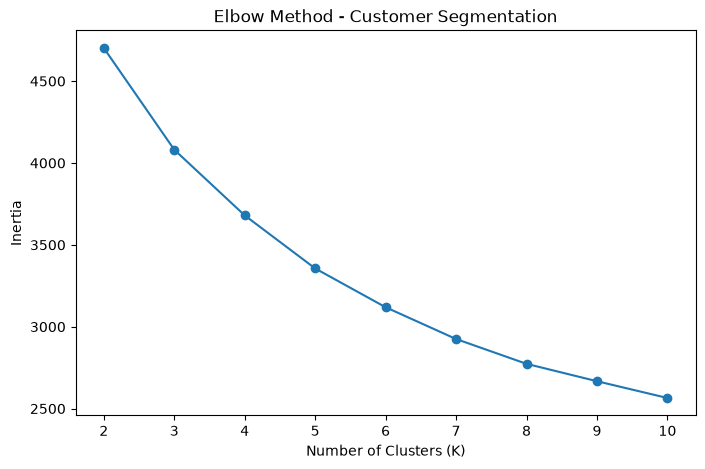

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Customer Segmentation")
plt.xticks(list(k_values))

plt.show()

In [37]:
# Silhouette Score
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(customer_scaled)
    
    score = silhouette_score(
        customer_scaled,
        cluster_labels
    )
    
    silhouette_values.append(score)

print("K values:", list(k_values))
print("Silhouette scores:", silhouette_values)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Silhouette scores: [0.2762916531529904, 0.18135933154803605, 0.16314272489855078, 0.16693024213846946, 0.16344289074266688, 0.1639525355324282, 0.16427917576211515, 0.15774204319964333, 0.1557284428019333]


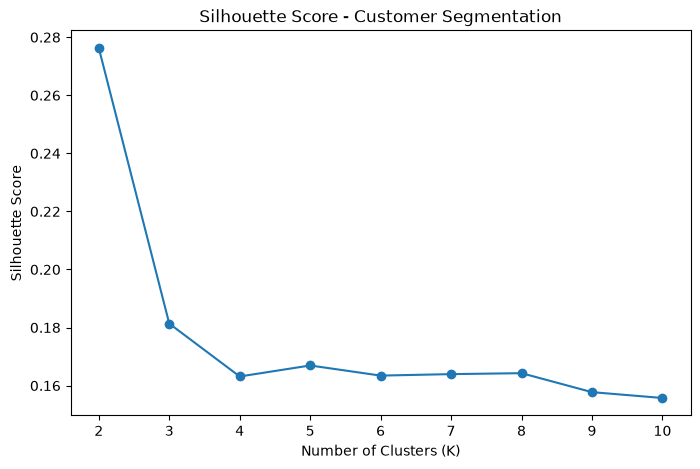

In [38]:
# Visualise
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score - Customer Segmentation")
plt.xticks(list(k_values))

plt.show()

" K=2 was selected because it produced the highest Silhouette Score (0.2763), while the Elbow Method showed diminishing returns as K increased. The resulting segments separate customers primarily by ordering frequency and total spending rather than by average order value. "

In [39]:
# Train the Final K-Means Model
optimal_k = 2

final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

customer_clusters = final_kmeans.fit_predict(customer_scaled)

In [40]:
customer_features["cluster"] = customer_clusters

In [41]:
# Check Cluster Sizes
print(
    customer_features["cluster"].value_counts().sort_index()
)

cluster
0    594
1    406
Name: count, dtype: int64


In [42]:
cluster_distribution = (
    customer_features["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print(cluster_distribution)

cluster
0    59.4
1    40.6
Name: proportion, dtype: float64


In [43]:
# Create Customer Cluster Profiles
customer_cluster_profile = (
    customer_features
    .groupby("cluster")
    [
        [
            "total_orders",
            "avg_order_value",
            "total_spending",
            "ordering_frequency",
            "weekend_orders",
            "late_night_orders",
            "avg_rating_given"
        ]
    ]
    .mean()
)

customer_cluster_profile

,total_orders,avg_order_value,total_spending,ordering_frequency,weekend_orders,late_night_orders,avg_rating_given
cluster,,,,,,,
0,7.941077,1056.272143,8344.959394,2.784792,2.144781,2.143098,3.874379
1,13.012315,1099.258437,14247.728522,4.374384,4.061576,4.014778,3.882405


In [44]:
# Calculate the cluster size
customer_cluster_profile["customer_count"] = (
    customer_features
    .groupby("cluster")
    .size()
)
customer_cluster_profile

,total_orders,avg_order_value,total_spending,ordering_frequency,weekend_orders,late_night_orders,avg_rating_given,customer_count
cluster,,,,,,,,
0,7.941077,1056.272143,8344.959394,2.784792,2.144781,2.143098,3.874379,594
1,13.012315,1099.258437,14247.728522,4.374384,4.061576,4.014778,3.882405,406


In [45]:
# Add Business Names to Your Data
cluster_names = {
    0: "Occasional Lower-Value Customers",
    1: "Frequent High-Value Customers"
}
customer_features["cluster_name"] = (
    customer_features["cluster"]
    .map(cluster_names)
)
customer_features[
    ["customer_id", "cluster", "cluster_name"]
].head()

,customer_id,cluster,cluster_name
0,C0001,0,Occasional Lower-Value Customers
1,C0002,0,Occasional Lower-Value Customers
2,C0003,1,Frequent High-Value Customers
3,C0004,0,Occasional Lower-Value Customers
4,C0005,0,Occasional Lower-Value Customers


In [46]:
# Create a Clean Cluster Profile
customer_cluster_profile = (
    customer_features
    .groupby(["cluster", "cluster_name"])
    [
        [
            "total_orders",
            "avg_order_value",
            "total_spending",
            "ordering_frequency",
            "weekend_orders",
            "late_night_orders",
            "avg_rating_given"
        ]
    ]
    .mean()
    .round(2)
)

customer_cluster_profile

,,total_orders,avg_order_value,total_spending,ordering_frequency,weekend_orders,late_night_orders,avg_rating_given
cluster,cluster_name,,,,,,,
0,Occasional Lower-Value Customers,7.94,1056.27,8344.96,2.78,2.14,2.14,3.87
1,Frequent High-Value Customers,13.01,1099.26,14247.73,4.37,4.06,4.01,3.88
